Python DA Assignment 2 - Data Visualization

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("taxis")
print(df.shape)
df.head()

In [2]:
df.info()
print()
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [3]:

for col in ["payment", "dropoff_zone", "dropoff_borough"]:
    df[col] = df[col].fillna(df[col].mode()[0])


df = df.dropna(subset=["pickup_zone", "pickup_borough"])


print(df.isnull().sum())
print(df.shape)

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
(6407, 14)


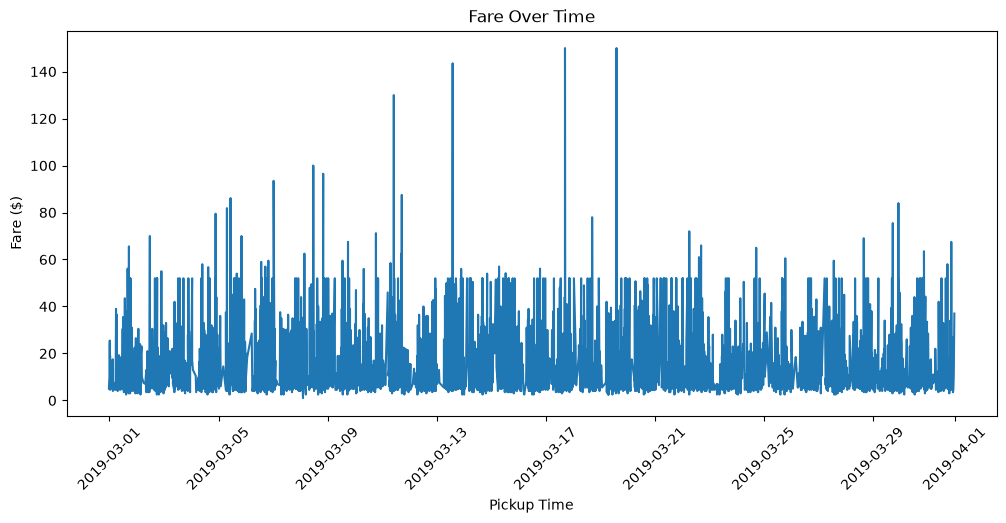

In [4]:
df["pickup"] = pd.to_datetime(df["pickup"])
df_sorted = df.sort_values("pickup")

plt.figure(figsize=(12, 5))
plt.plot(df_sorted["pickup"], df_sorted["fare"])
plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.show()

pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    58753.42
Queens       16382.06
Name: fare, dtype: float64


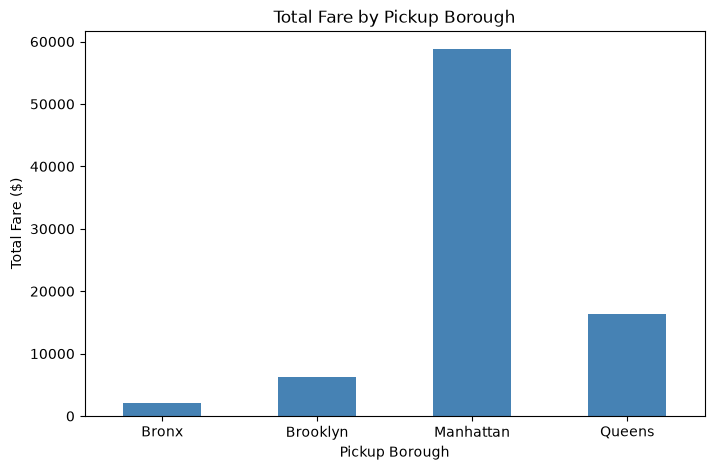

In [5]:
fare_by_borough = df.groupby("pickup_borough")["fare"].sum()
print(fare_by_borough)

fare_by_borough.plot(kind="bar", figsize=(8, 5), color="steelblue")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=0)
plt.show()

payment
credit card    4600
cash           1807
Name: count, dtype: int64


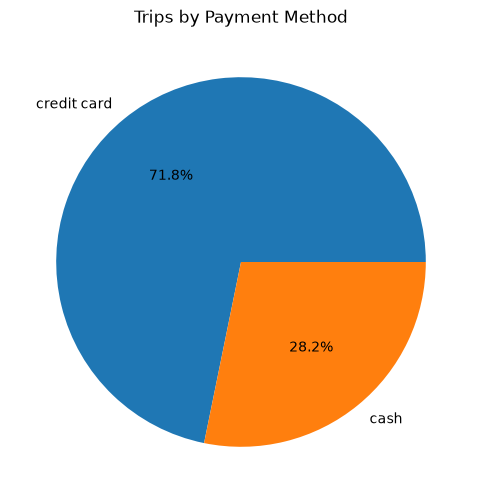

In [6]:
payment_counts = df["payment"].value_counts()
print(payment_counts)

payment_counts.plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6))
plt.title("Trips by Payment Method")
plt.ylabel("")
plt.show()

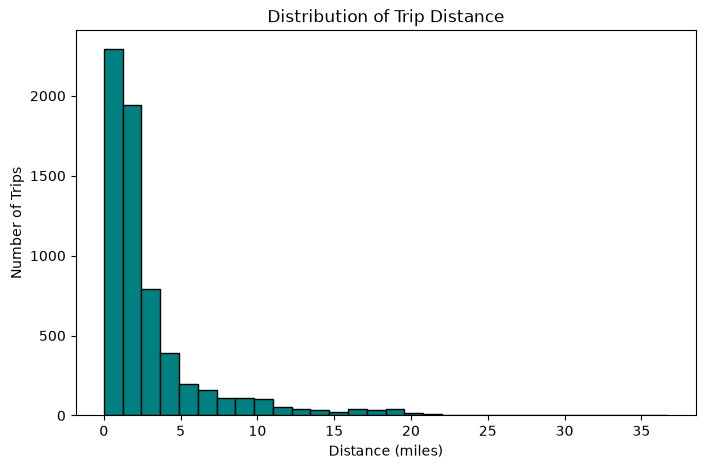

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(df["distance"], bins=30, color="teal", edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of Trips")
plt.show()

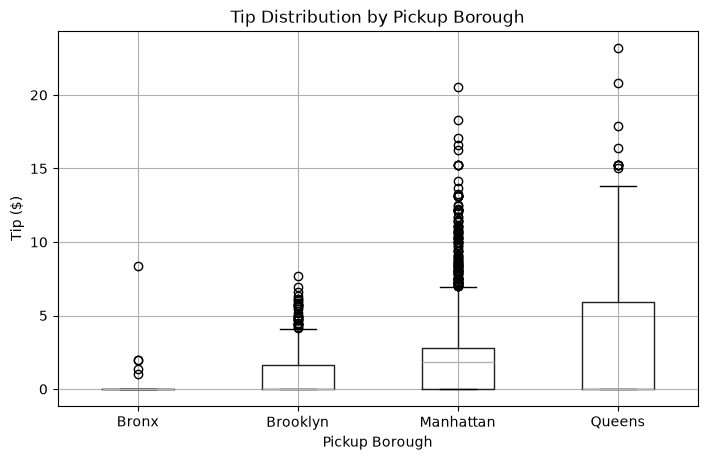

In [8]:
df.boxplot(column="tip", by="pickup_borough", figsize=(8, 5))
plt.title("Tip Distribution by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip ($)")
plt.show()

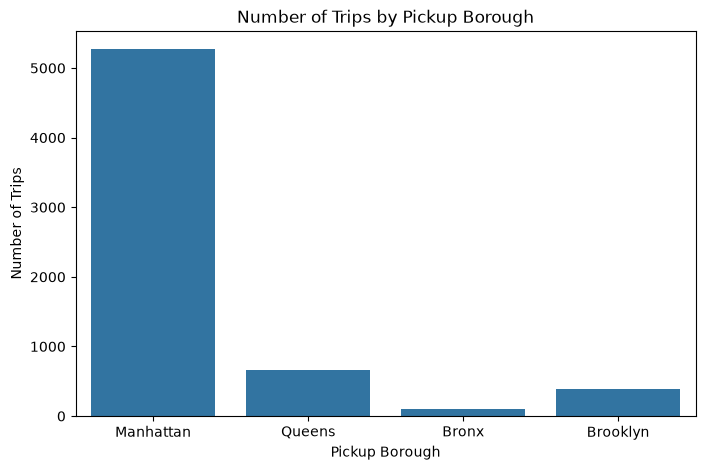

In [9]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="pickup_borough")
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.show()

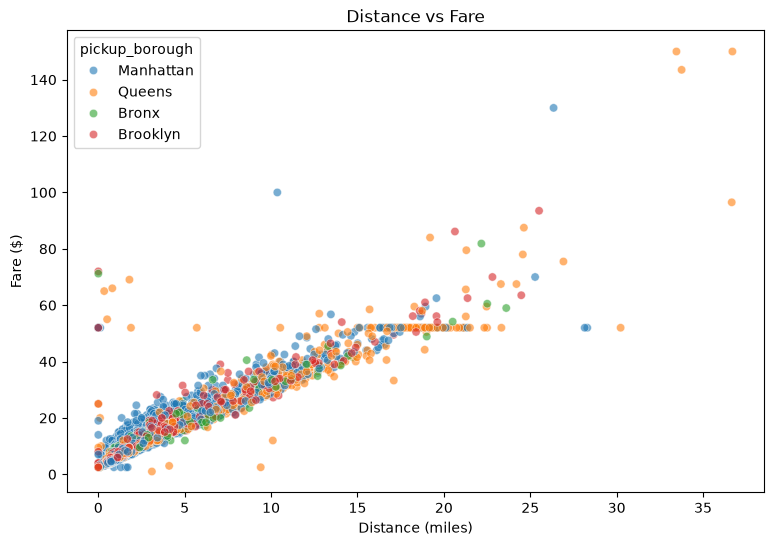

In [10]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough", alpha=0.6)
plt.title("Distance vs Fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.show()

          distance      fare       tip     tolls     total
distance  1.000000  0.938783  0.463935  0.639339  0.924426
fare      0.938783  1.000000  0.469023  0.609828  0.973744
tip       0.463935  0.469023  1.000000  0.405218  0.631109
tolls     0.639339  0.609828  0.405218  1.000000  0.684341
total     0.924426  0.973744  0.631109  0.684341  1.000000


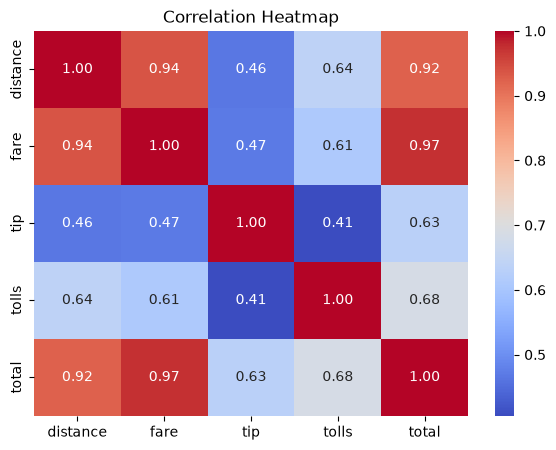

In [11]:
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()
print(corr)

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

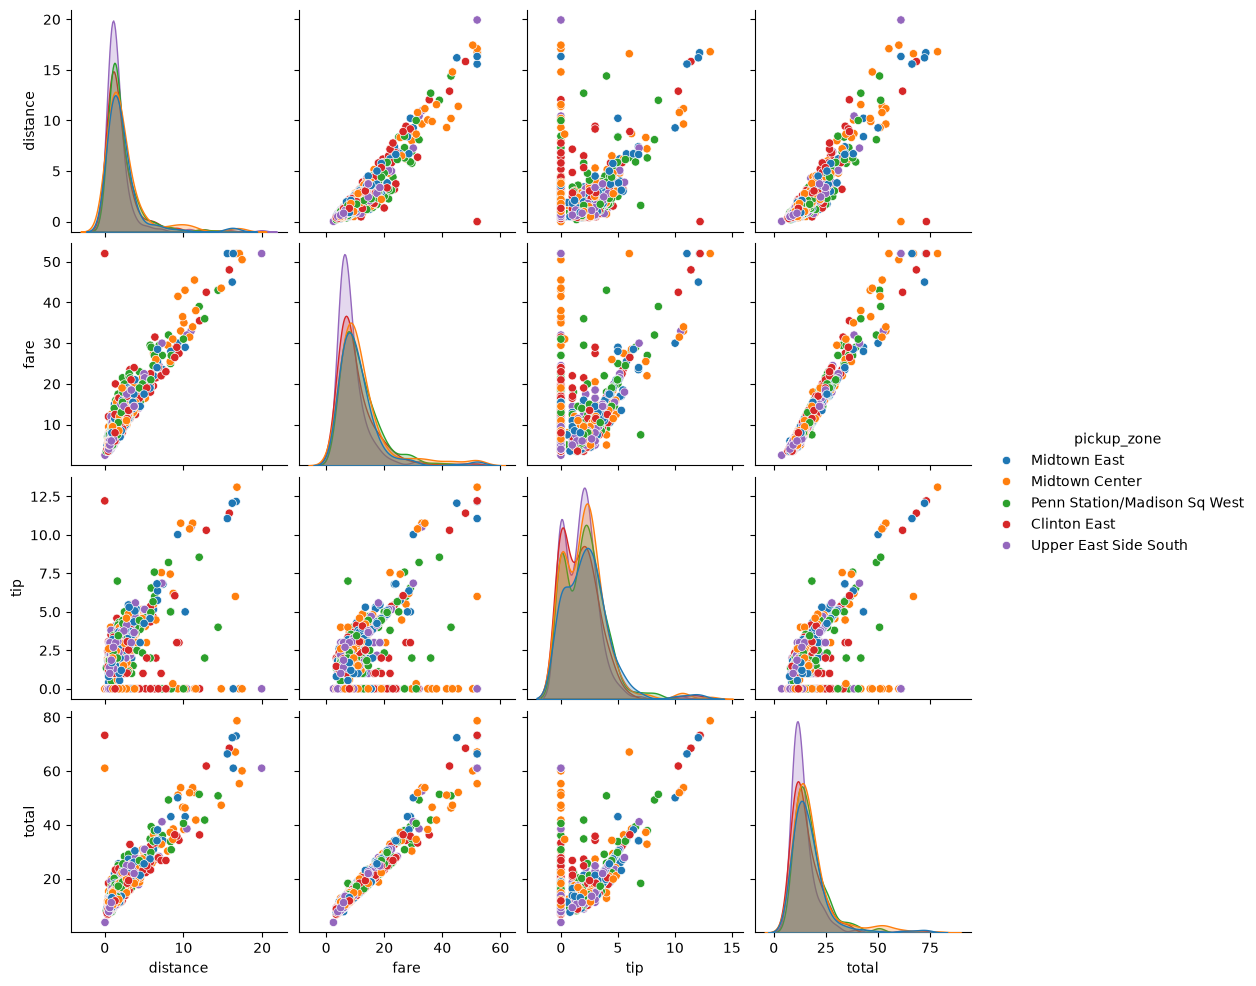

In [12]:
top_zones = df["pickup_zone"].value_counts().head(5).index
subset = df[df["pickup_zone"].isin(top_zones)]

sns.pairplot(subset[["distance", "fare", "tip", "total", "pickup_zone"]],
             hue="pickup_zone")
plt.show()

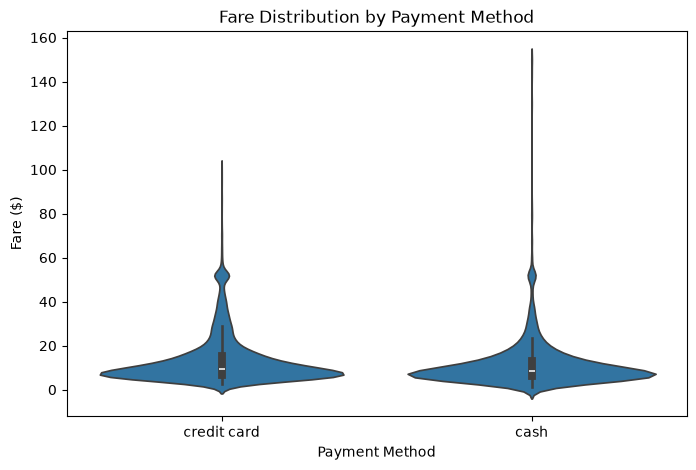

In [14]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="payment", y="fare")
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.show()